In [24]:

import pandas as pd
imputed_df = pd.read_csv("imputed_df.csv")
print(imputed_df.shape)
imputed_df.head()


(2796, 10)


,element,Z,A,N,N/Z,Q_beta_keV,Q_alpha_keV,S_n_keV,S_p_keV,log_half_life
0,H,1,3.0,2,2.000000,18.5906,-285.00,6257.233,5571.50,8.589715
1,HE,2,6.0,4,2.000000,3505.2200,-285.00,1710.000,5571.50,-0.093288
2,BE,4,7.0,3,0.750000,551.4500,-1587.13,10677.000,5606.85,6.662589
3,HE,2,8.0,6,3.000000,10663.8800,-285.00,2535.000,5571.50,-0.924088
4,LI,3,8.0,5,1.666667,16004.1300,-285.00,2032.620,12416.00,-0.075772


In [25]:
#drop the Z and N columns from the imputed_df dataframe
imputed_df = imputed_df.drop(columns=['Z', 'N'])
imputed_df.head()

,element,A,N/Z,Q_beta_keV,Q_alpha_keV,S_n_keV,S_p_keV,log_half_life
0,H,3.0,2.000000,18.5906,-285.00,6257.233,5571.50,8.589715
1,HE,6.0,2.000000,3505.2200,-285.00,1710.000,5571.50,-0.093288
2,BE,7.0,0.750000,551.4500,-1587.13,10677.000,5606.85,6.662589
3,HE,8.0,3.000000,10663.8800,-285.00,2535.000,5571.50,-0.924088
4,LI,8.0,1.666667,16004.1300,-285.00,2032.620,12416.00,-0.075772


In [28]:
from sklearn.model_selection import train_test_split
df_train, df_test = train_test_split(
    imputed_df,
    test_size=0.2,  # 20% for testing
    random_state=42  # Ensure reproducibility
)
print(df_train.shape)
df_train.head()

(2236, 8)


,element,A,N/Z,Q_beta_keV,Q_alpha_keV,S_n_keV,S_p_keV,log_half_life
1961,YB,182.0,1.600000,2580.0,-1210.0,6080.0,10860.0,-6.795880
1465,LA,147.0,1.578947,5336.0,-1428.0,5529.0,9101.0,0.608526
879,MO,104.0,1.476190,2151.0,-6399.0,7460.0,12620.0,1.778151
238,TI,44.0,1.000000,-13749.0,-5127.1,16318.0,8649.4,9.270691
1641,ND,159.0,1.650000,6830.0,-4370.0,3960.0,12860.0,-0.314258


Feature coverage
---------------------------------------------
A                           2236/2236   (100.0%)
N/Z                         2236/2236   (100.0%)
Q_beta_keV                  2236/2236   (100.0%)
Q_alpha_keV                 2236/2236   (100.0%)
S_n_keV                     2236/2236   (100.0%)
S_p_keV                     2236/2236   (100.0%)
Top 10 features by absolute Pearson correlation:


,Pearson,Spearman
Q_beta_keV,-0.154612,-0.197102
A,0.113656,0.147311
N/Z,-0.086770,-0.149994
Q_alpha_keV,0.055631,0.060227
S_p_keV,-0.015222,0.096690
S_n_keV,-0.008789,0.127214


Top 10 features by absolute Spearman correlation:


,Pearson,Spearman
Q_beta_keV,-0.154612,-0.197102
N/Z,-0.086770,-0.149994
A,0.113656,0.147311
S_n_keV,-0.008789,0.127214
S_p_keV,-0.015222,0.096690
Q_alpha_keV,0.055631,0.060227


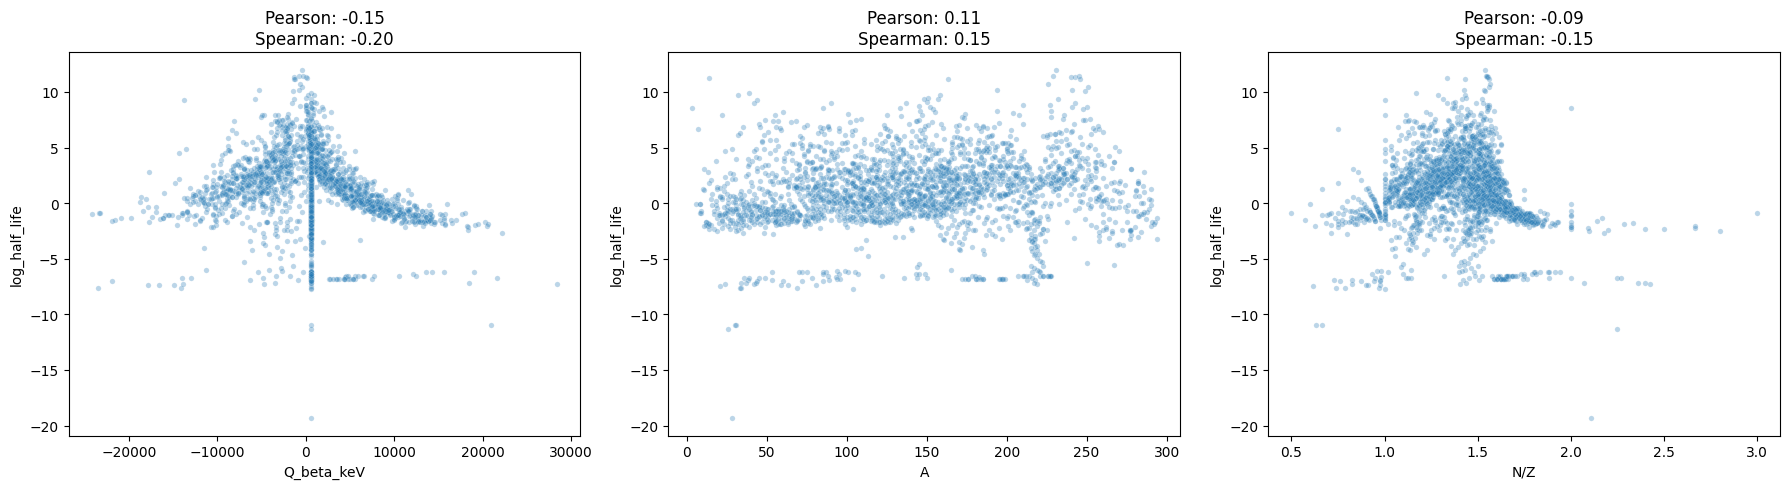

In [34]:
#Quick EDA on training set 
features = [
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

TARGET = df_train['log_half_life'].name

print("Feature coverage")
print("-" * 45)

for feature in features:
    available = sum(
        df_train[feature].notnull() & (df_train[feature] != "")
    )

    total = len(df_train)
    percentage = 100 * available / total if total else 0

    print(
        f"{feature:25s} "
        f"{available:6d}/{total:<6d} "
        f"({percentage:.1f}%)"
    )


import seaborn as sns
eda_target = TARGET

X = df_train[features]
y = df_train[eda_target]

# Calculate each feature's correlation with the target
correlations = pd.DataFrame({
    "Pearson": X.corrwith(y, method="pearson"),
    "Spearman": X.corrwith(y, method="spearman")
})

# Show the strongest correlations, including negative correlations
for method in ["Pearson", "Spearman"]:
    print(f"Top 10 features by absolute {method} correlation:")
    display(
        correlations.sort_values(
            by=method, key=lambda values: values.abs(), ascending=False
        ).head(10)
    )

# Plot the three features with the strongest Pearson correlations
top_features = correlations["Pearson"].abs().nlargest(3).index

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, top_features):
    sns.scatterplot(
        data=df_train,
        x=feature,
        y=eda_target,
        alpha=0.3,
        s=15,
        ax=ax
    )
    ax.set_title(
        f"Pearson: {correlations.loc[feature, 'Pearson']:.2f}\n"
        f"Spearman: {correlations.loc[feature, 'Spearman']:.2f}"
    )

plt.tight_layout()
plt.show()

<Figure size 1200x800 with 0 Axes>

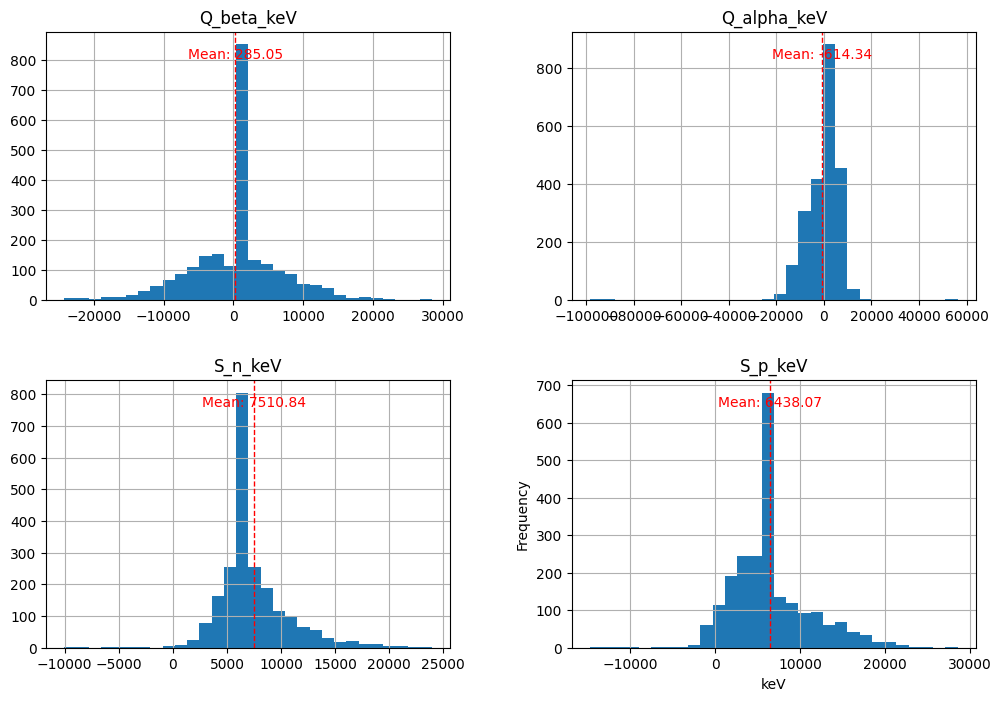

In [36]:
plt.figure(figsize=(12, 8))
df_train[["Q_beta_keV", "Q_alpha_keV", "S_n_keV", "S_p_keV"]].hist(bins=30, figsize=(12, 8))
#display means of each feature
for i, feature in enumerate(["Q_beta_keV", "Q_alpha_keV", "S_n_keV", "S_p_keV"]):
    mean_value = df_train[feature].mean()
    plt.subplot(2, 2, i + 1)
    plt.axvline(mean_value, color='red', linestyle='dashed', linewidth=1)
    plt.text(mean_value, plt.ylim()[1] * 0.9, f'Mean: {mean_value:.2f}', color='red', ha='center')
plt.xlabel("keV")
plt.ylabel("Frequency")
plt.show()


In [45]:
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import max_error, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
#PREPROCESSING STEPS
dummyregressor_mean = DummyRegressor(strategy="mean")
dummyregressor_median = DummyRegressor(strategy="median")
dummyregressor_mean.fit(df_train[features], df_train[TARGET])
dummyregressor_median.fit(df_train[features], df_train[TARGET])


def get_regression_metrics(model, X, y_true):

    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)
    mape = mean_absolute_percentage_error(y_true, y_predicted)

    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'max_error': maximum_error,
        'mape': mape
    }

    return metrics_dict


dummy_regressors = [
    ('mean', dummyregressor_mean),
    ('median', dummyregressor_median)
]

dummy_regressor_results_test = {} # initialize empty dictionary
dummy_regressor_results_train = {}


for regressorname, regressor in dummy_regressors:
    print(f"Calculating metrics for {regressorname}")
    dummy_regressor_results_test[regressorname] = get_regression_metrics(regressor, df_test[features], df_test[TARGET])
    dummy_regressor_results_train[regressorname] = get_regression_metrics(regressor, df_train[features], df_train[TARGET])


print("Dummy Regressor Results - Train & Test Set")

for regressorname, metrics in dummy_regressor_results_train.items():
    print(f"{regressorname} (Train): {metrics}")

for regressorname, metrics in dummy_regressor_results_test.items():
    print(f"{regressorname} (Test): {metrics}")

Calculating metrics for mean
Calculating metrics for median
Dummy Regressor Results - Train & Test Set
mean (Train): {'mae': 2.4027006709556904, 'mse': 10.236687443723449, 'max_error': 20.52017550011241, 'mape': 11912920644616.928}
median (Train): {'mae': 2.401670452026296, 'mse': 10.245344364276827, 'max_error': 20.42713292623692, 'mape': 10975920418688.215}
mean (Test): {'mae': 2.4571366173932594, 'mse': 10.448832757773094, 'max_error': 11.194600506888646, 'mape': 1.8892598356397436}
median (Test): {'mae': 2.4515085207556777, 'mse': 10.408802547891344, 'max_error': 11.287643080764138, 'mape': 1.7968921546546894}


In [63]:
#scaling the features using StandardScaler, MinMaxScaler, and RobustScaler
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
scaler = StandardScaler()

df_train_scaled = pd.DataFrame(scaler.fit_transform(df_train[features]), columns=features)

df_test_scaled = pd.DataFrame(scaler.transform(df_test[features]), columns=features)

linear_regressor = LinearRegression()

linear_regressor.fit(df_train_scaled[features], df_train[TARGET])

linear_regressor_results_train = get_regression_metrics(linear_regressor, df_train_scaled[features], df_train[TARGET])
linear_regressor_results_test = get_regression_metrics(linear_regressor, df_test_scaled[features], df_test[TARGET])

print("Linear Regressor Results - Train Set:")
print(linear_regressor_results_train)
print("Linear Regressor Results - Test Set:")
print(linear_regressor_results_test)


Linear Regressor Results - Train Set:
{'mae': 2.248437950495211, 'mse': 9.386203007153808, 'max_error': 21.645150696735403, 'mape': 17357800731974.482}
Linear Regressor Results - Test Set:
{'mae': 2.2736768980194384, 'mse': 9.370565134206544, 'max_error': 10.499873768294737, 'mape': 1.9238098371390313}
